# C3: Sentiment Analysis

**Sentiment Analysis** (also known as opinion mining) is the process of determining the emotional tone behind a series of words. It is used to get an understanding of the attitudes, opinions, and emotions expressed within an online mention.

![](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fwww.researchgate.net%2Fpublication%2F371481205%2Ffigure%2Ffig1%2FAS%3A11431281168479955%401686993652854%2FBlock-diagram-showing-the-Sentiment-Analysis-process.png&f=1&nofb=1&ipt=279de4d8508edb68d54da6308f582bdff693d135d7a831babad0c22e431e264e)

## 1. Approaches to Sentiment Analysis

There are two main ways to do this:

### A. Lexicon-Based (Rule-Based)
*   **How it works**: Uses a dictionary (lexicon) where every word has a pre-defined score (e.g., "good" = +1, "terrible" = -1).
*   **Pros**: Fast, no training data needed, easy to understand.
*   **Cons**: Struggles with sarcasm, context, and new slang words not in the dictionary.
*   **Examples**: TextBlob, VADER.

### B. Machine Learning-Based
*   **How it works**: Uses a large dataset of labeled examples (sentences marked as Positive/Negative) to train a model to *predict* sentiment.
*   **Pros**: Can learn context and complexities, generally more accurate on specific domains.
*   **Cons**: Needs a lot of labeled training data.
*   **Examples**: Naive Bayes, Logistic Regression, Deep Learning (BERT).

### Visual Comparison

![Lexicon vs ML](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fwww.researchgate.net%2Fpublication%2F353641714%2Ffigure%2Ffig2%2FAS%3A1052342480801792%401627909407927%2FDiagram-of-sentiment-analysis-methods.png&f=1&nofb=1&ipt=8d32916db2d486912d4cbc92d4a0e7aa86a7c91c9e0f78cefa105e06c3477f02)

## 2. Setup Libraries

We will need `textblob` and `vaderSentiment`.

In [ ]:
# !pip install textblob vaderSentiment pandas matplotlib seaborn

## 3. Lexicon-Based: TextBlob

**TextBlob** returns two properties:
1.  **Polarity**: How positive or negative the text is (Range: -1 to +1).
2.  **Subjectivity**: How factual or opinionated the text is (Range: 0 to 1).
    *   0 = Fact
    *   1 = Opinion

In [2]:
from textblob import TextBlob

text1 = "I love NLP! It is purely amazing and wonderful."
text2 = "The phone keeps crashing. It is terrible."
text3 = "The Earth revolves around the Sun."

for t in [text1, text2, text3]:
    blob = TextBlob(t)
    print(f"Text: '{t}'")
    print(f"  Polarity: {blob.sentiment.polarity:.2f} (Positive/Negative)")
    print(f"  Subjectivity: {blob.sentiment.subjectivity:.2f} (Fact/Opinion)")
    print("-"*30)

Text: 'I love NLP! It is purely amazing and wonderful.'
  Polarity: 0.74 (Positive/Negative)
  Subjectivity: 0.83 (Fact/Opinion)
------------------------------
Text: 'The phone keeps crashing. It is terrible.'
  Polarity: -1.00 (Positive/Negative)
  Subjectivity: 1.00 (Fact/Opinion)
------------------------------
Text: 'The Earth revolves around the Sun.'
  Polarity: 0.00 (Positive/Negative)
  Subjectivity: 0.00 (Fact/Opinion)
------------------------------


## 4. Lexicon-Based: VADER

**VADER** (Valence Aware Dictionary and sEntiment Reasoner) is specifically tuned for sentiments expressed in **social media**.

**Key Features**:
*   Understands capitalization (`GOOD` is more positive than `good`).
*   Understands punctuation (`Good!!!` is more positive than `Good`).
*   Understands emojis (:D, :( ).
*   Understands negation (`Not good`).

It returns a `compound` score:
*   **> 0.05**: Positive
*   **< -0.05**: Negative
*   **Between**: Neutral

In [3]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

social_texts = [
    "This movie is good.",
    "This movie is GOOD!",
    "This movie is GOOD!!! :)",
    "The movie was not good."
]

for t in social_texts:
    scores = analyzer.polarity_scores(t)
    print(f"Text: '{t}'")
    print(f"  Compound Score: {scores['compound']:.2f}")
    print(f"  Details: {scores}")
    print("-"*30)

Text: 'This movie is good.'
  Compound Score: 0.44
  Details: {'neg': 0.0, 'neu': 0.508, 'pos': 0.492, 'compound': 0.4404}
------------------------------
Text: 'This movie is GOOD!'
  Compound Score: 0.60
  Details: {'neg': 0.0, 'neu': 0.433, 'pos': 0.567, 'compound': 0.6027}
------------------------------
Text: 'This movie is GOOD!!! :)'
  Compound Score: 0.82
  Details: {'neg': 0.0, 'neu': 0.285, 'pos': 0.715, 'compound': 0.8181}
------------------------------
Text: 'The movie was not good.'
  Compound Score: -0.34
  Details: {'neg': 0.376, 'neu': 0.624, 'pos': 0.0, 'compound': -0.3412}
------------------------------


## 5. Practical Application: Product Reviews

Let's compare TextBlob and VADER on our real data.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv('../../00-data/NLP Product Reviews.csv')
df['Text'] = df['Text'].fillna('')

# Functions to get scores
def get_textblob_score(text):
    return TextBlob(text).sentiment.polarity

def get_vader_score(text):
    return analyzer.polarity_scores(text)['compound']

# Apply to ALL reviews
df['TextBlob_Score'] = df['Text'].apply(get_textblob_score)
df['VADER_Score'] = df['Text'].apply(get_vader_score)

print(df[['Text', 'TextBlob_Score', 'VADER_Score']].head(5))

                                                Text  TextBlob_Score  \
0  I have bought several of the Vitality canned d...        0.450000   
1  Product arrived labeled as Jumbo Salted Peanut...       -0.033333   
2  This is a confection that has been around a fe...        0.133571   
3  If you are looking for the secret ingredient i...        0.166667   
4  Great taffy at a great price.  There was a wid...        0.483333   

   VADER_Score  
0       0.9441  
1      -0.5664  
2       0.8138  
3       0.4404  
4       0.9468  


### Visualization
Let's see the distribution of sentiments.

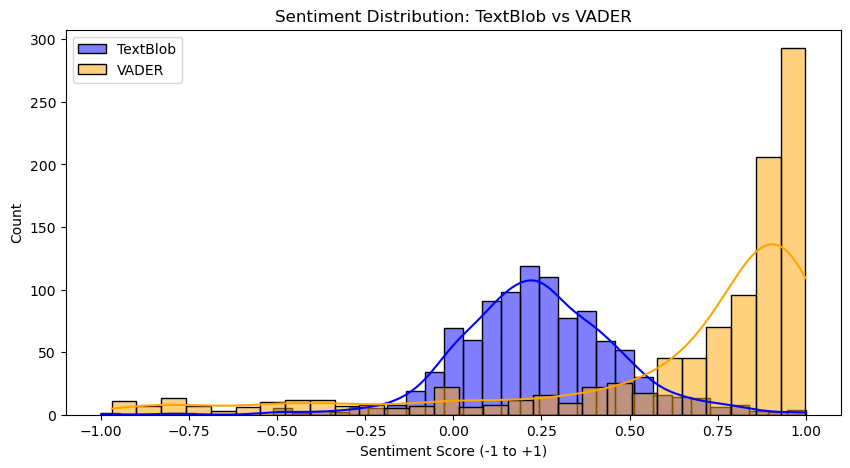

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df['TextBlob_Score'], color='blue', label='TextBlob', kde=True)
sns.histplot(df['VADER_Score'], color='orange', label='VADER', kde=True)
plt.title("Sentiment Distribution: TextBlob vs VADER")
plt.xlabel("Sentiment Score (-1 to +1)")
plt.legend()
plt.show()

### Disagreement Analysis
Where do they disagree the most? Let's finding reviews where VADER thinks it's positive but TextBlob thinks it's negative.

In [6]:
# VADER is Positive (> 0.5) AND TextBlob is Negative (< 0)
conflict = df[(df['VADER_Score'] > 0.5) & (df['TextBlob_Score'] < 0)]

if not conflict.empty:
    print("Conflict Example (VADER says +, TextBlob says -):")
    print(conflict['Text'].iloc[0])
    print(f"VADER: {conflict['VADER_Score'].iloc[0]}, TextBlob: {conflict['TextBlob_Score'].iloc[0]}")
else:
    print("No major conflicts found in this small subset.")

Conflict Example (VADER says +, TextBlob says -):
The Strawberry Twizzlers are my guilty pleasure - yummy. Six pounds will be around for a while with my son and I.
VADER: 0.6486, TextBlob: -0.5


## 6. Machine Learning Concept

While we used pre-made dictionaries above, the **Machine Learning** approach would look like this:

1.  **Label Data**: Humans read 1000 reviews and label them 1 (Pos) or 0 (Neg).
2.  **Vectorize**: Convert reviews to TF-IDF vectors (from Notebook C2).
3.  **Train**: Teach a model (Logistic Regression) to recognize that high TF-IDF for "terrible" = 0 and "amazing" = 1.
4.  **Predict**: Feed new text to the model.

As you can see, TF-IDF is the bridge between text and the ML model.

## 7. Exercises

### Exercise 1: Custom TextBlob
Analyze the following sentence. Is it subjective?

`sentence = "I think chocolate ice cream is the best flavor in the world."`

In [7]:
# Your Code Here


### Exercise 2: VADER Emojis
Does VADER understand this slang/emoji sentence?

`sentence = "The food was meh :/"`

In [8]:
# Your Code Here


### Exercise 3: Most Positive Review
Find the review in our dataframe `df` that has the highest VADER score.

In [9]:
# Your Code Here
